# 실습 3. Attention과 Transformer

**3a. Self-attention 직접 구현** — Scaled dot-product attention, 마스킹, Multi-head
**3b. 사전학습 모델의 attention 시각화** — Hugging Face BERT

**목표**
- Query·Key·Value 연산을 코드 몇 줄로 구현하며 수식을 체감
- PyTorch 내장 모듈과 결과를 대조해 구현 검증
- 실제 언어 모델이 문맥 속 단어 관계를 어떻게 포착하는지 관찰

## 0. 환경 설정

In [14]:
# transformers: Hugging Face의 사전학습 모델(BERT 등) 라이브러리
# koreanize-matplotlib: 그래프 한글 깨짐 방지
# -q: 설치 로그를 조용히(quiet) 출력
!pip -q install transformers koreanize-matplotlib

In [15]:
import koreanize_matplotlib   # 그래프 한글 표시 (import만 하면 자동 적용)
import math                   # sqrt, log 등 수학 함수
import torch                  # PyTorch 기본 패키지
import torch.nn as nn         # 신경망 레이어 (Linear 등)
import torch.nn.functional as F   # softmax 등 함수형 API
import matplotlib.pyplot as plt   # 시각화

torch.manual_seed(0)      # 난수 시드 고정 → 임베딩·가중치 초기값이 매번 같게 (재현성)

---
# 3a. Self-attention 직접 구현

## 1. Scaled dot-product attention

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- $QK^\top$: 각 토큰(Query)이 다른 토큰(Key)과 얼마나 관련 있는지 점수 계산
- $\sqrt{d_k}$로 나눔: 차원이 커질 때 softmax 포화 방지
- 가중치로 Value를 가중 평균

In [16]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    # Q, K, V: (..., seq_len, d_k)
    #   "..." 자리에는 배치·head 차원이 몇 개든 올 수 있음 → 한 함수로 single/multi-head 모두 처리
    d_k = Q.size(-1)                                       # 마지막 차원 = 벡터 길이 d_k

    # (1) 유사도 점수: Q와 K의 내적 → "i번째 토큰이 j번째 토큰을 얼마나 참고할지"
    #     K.transpose(-2, -1): (seq, d_k) → (d_k, seq) 로 뒤집어 행렬곱 가능하게
    #     √d_k로 나누는 이유: 차원이 크면 내적 값이 커져 softmax가 한쪽으로 쏠림(포화) → 기울기 소실
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)     # (..., seq, seq)

    # (2) 마스킹: mask가 0인 위치는 -inf로 → softmax 후 정확히 0이 되어 "못 보게" 됨
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    # (3) softmax: 각 행(Query 하나)의 점수를 확률처럼 바꿈 → 행 합 = 1
    weights = F.softmax(scores, dim=-1)                    # 행 합 = 1

    # (4) 가중 평균: 가중치대로 Value를 섞어 새로운 표현을 만듦
    return weights @ V, weights                            # (출력, attention 가중치)

# ============================================================
# [실행 결과 해설]
# ============================================================
# (출력 없음) 함수 정의만 하는 셀. 아래 셀들에서 이 함수를 계속 재사용함

## 2. 장난감 예제
- 토큰 5개, 임베딩 차원 8
- 학습 가능한 선형 변환 $W_Q, W_K, W_V$로 Q·K·V 생성

출력 크기: torch.Size([5, 8])
행 합: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


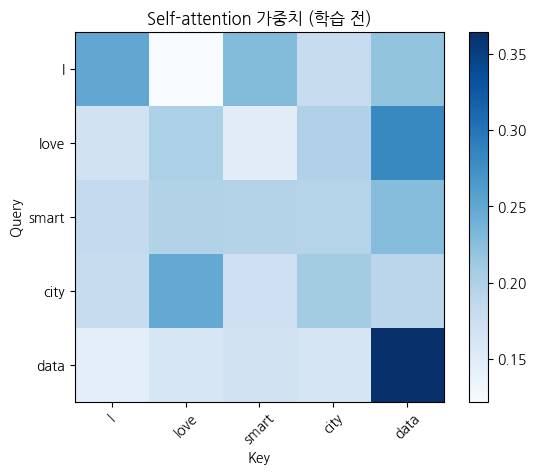

In [17]:
tokens = ["I", "love", "smart", "city", "data"]
seq_len, d_model = len(tokens), 8          # 토큰 5개, 각 토큰은 8차원 벡터

# 실제로는 학습된 임베딩을 쓰지만, 여기서는 무작위 벡터로 대체
X = torch.randn(seq_len, d_model)          # 토큰 임베딩 (예시)  (5, 8)

# 같은 입력 X를 세 가지 "역할"로 바꾸는 선형 변환
#   Query: 내가 찾고 싶은 것 / Key: 내가 가진 특징(검색용 꼬리표) / Value: 실제로 전달할 내용
W_Q = nn.Linear(d_model, d_model, bias=False)
W_K = nn.Linear(d_model, d_model, bias=False)
W_V = nn.Linear(d_model, d_model, bias=False)

Q, K, V = W_Q(X), W_K(X), W_V(X)           # 각각 (5, 8)
out, attn = scaled_dot_product_attention(Q, K, V)
print("출력 크기:", out.shape)              # 입력과 같은 (5, 8): 토큰마다 문맥이 섞인 새 벡터
print("행 합:", attn.sum(-1))               # softmax 덕분에 모두 1이어야 함

# ===== attention 가중치를 히트맵으로 그리는 함수 =====
def show_attn(w, labels, title):
    plt.imshow(w.detach(), cmap="Blues")   # 진할수록 가중치가 큼. detach(): 기울기 추적 분리
    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.yticks(range(len(labels)), labels)
    plt.xlabel("Key"); plt.ylabel("Query"); plt.title(title); plt.colorbar()
    # 읽는 법: (행=Query i, 열=Key j) 칸 = "i가 j를 얼마나 참고하는가"
    plt.show()

show_attn(attn, tokens, "Self-attention 가중치 (학습 전)")

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 출력 크기 (5, 8): 입력 X와 같은 모양. 토큰 5개가 각각 "문맥이 섞인" 8차원 벡터로 바뀜
# - 행 합이 모두 1.0000: softmax가 각 Query 행을 확률 분포로 만들었음을 확인
#   (grad_fn=<SumBackward1>는 W_Q 등이 학습 가능한 파라미터라 기울기 추적 중이라는 표시일 뿐)
# - 히트맵: W_Q·W_K·W_V가 무작위 초기값이고 X도 무작위라 패턴에 언어적 의미는 없음
#   → 학습을 거쳐야 "의미 있는 단어끼리 높은 가중치"가 생김. 지금은 계산 과정 확인용

## 3. Causal mask — GPT 계열(디코더)의 핵심
- 각 토큰은 **자신과 이전 토큰만** 참조 → 다음 단어 예측 시 미래 정보 차단

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])


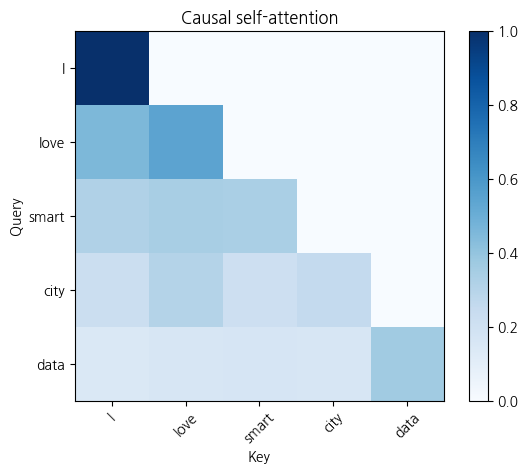

In [18]:
# 하삼각 행렬(lower triangular): 대각선 포함 아래쪽만 1, 위쪽(미래)은 0
# 행 i는 열 0~i(자신과 과거)만 1 → i번째 토큰은 미래 토큰을 볼 수 없음
causal = torch.tril(torch.ones(seq_len, seq_len))
print(causal)
_, attn_causal = scaled_dot_product_attention(Q, K, V, mask=causal)
show_attn(attn_causal, tokens, "Causal self-attention")

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 마스크 행렬: 대각선 포함 아래쪽만 1 → 위쪽(미래) 칸은 -inf로 바뀌어 softmax 후 정확히 0
# - 히트맵의 오른쪽 위 삼각형이 모두 흰색(0)인 것을 확인
#   · 첫 행 "I"는 자기 자신만 볼 수 있어 가중치가 1.0 하나
#   · 마지막 행 "data"는 5개 토큰 전부를 볼 수 있음
# - 의미: GPT처럼 다음 단어를 예측하는 모델은 학습 중 정답(미래 단어)을 미리 보면 안 되므로 필수

## 4. Multi-head attention
- 차원을 `n_heads`개로 나눠 각 head가 서로 다른 관계를 병렬로 학습
- 결과를 이어붙인(concat) 뒤 선형 변환

In [19]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0                 # 차원이 head 수로 나누어떨어져야 함
        self.h, self.d_k = n_heads, d_model // n_heads   # head 수, head당 차원 (8 / 2 = 4)
        self.W_qkv = nn.Linear(d_model, 3 * d_model)  # Q·K·V 변환을 한 번에 (8 → 24), 계산 효율 ↑
        self.W_o = nn.Linear(d_model, d_model)        # head 결과를 합친 뒤 섞어 주는 출력 변환

    def forward(self, x, mask=None):            # x: (batch, seq, d_model)
        B, T, D = x.shape                       # 배치, 토큰 수, 차원
        q, k, v = self.W_qkv(x).chunk(3, dim=-1)    # 24차원을 8·8·8로 3등분
        # (B, T, D) → (B, T, h, d_k) 로 쪼갠 뒤 → (B, h, T, d_k) 로 head 차원을 앞으로
        # → head마다 독립적인 (T, d_k) 행렬이 되어 attention을 병렬 계산
        split = lambda t: t.view(B, T, self.h, self.d_k).transpose(1, 2)
        q, k, v = split(q), split(k), split(v)
        out, w = scaled_dot_product_attention(q, k, v, mask)   # w: (B, h, T, T) head별 가중치
        # (B, h, T, d_k) → (B, T, h, d_k) → (B, T, D): head 결과를 다시 이어붙임(concat)
        # contiguous(): transpose로 흩어진 메모리를 연속으로 정리해야 view 가능
        out = out.transpose(1, 2).contiguous().view(B, T, D)   # head 결합
        return self.W_o(out), w

mha = MultiHeadAttention(d_model=8, n_heads=2)
y, w = mha(X.unsqueeze(0))                     # unsqueeze(0): (5, 8) → (1, 5, 8) 배치 차원 추가
print("출력:", y.shape, " head별 가중치:", w.shape)   # (1, 2, 5, 5)

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 출력 (1, 5, 8): 배치 1, 토큰 5, 차원 8 → 입력과 같은 모양 유지
# - 가중치 (1, 2, 5, 5): head 2개가 각자 5×5 attention 행렬을 따로 가짐
#   → 같은 문장을 서로 다른 관점(예: 문법 관계 / 의미 관계)으로 볼 수 있는 구조

출력: torch.Size([1, 5, 8])  head별 가중치: torch.Size([1, 2, 5, 5])


## 5. 구현 검증: PyTorch 내장 `nn.MultiheadAttention`과 비교
- 같은 가중치를 복사해 넣고 출력이 일치하는지 확인

In [20]:
# PyTorch 내장 구현 (batch_first=True → 입력 모양 (batch, seq, dim))
ref = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)

# 우리 구현의 가중치를 내장 모듈에 그대로 복사 → 같은 가중치면 출력도 같아야 함
with torch.no_grad():                                   # 복사는 학습이 아니므로 기울기 추적 끔
    ref.in_proj_weight.copy_(mha.W_qkv.weight)          # 내장 모듈도 Q·K·V를 하나의 (24×8) 행렬로 관리
    ref.in_proj_bias.copy_(mha.W_qkv.bias)
    ref.out_proj.weight.copy_(mha.W_o.weight)           # 출력 변환
    ref.out_proj.bias.copy_(mha.W_o.bias)

xb = X.unsqueeze(0)
y_ref, _ = ref(xb, xb, xb)                              # self-attention이므로 query=key=value=같은 입력
print("최대 오차:", (y - y_ref).abs().max().item())      # 두 출력의 차이 중 가장 큰 값
print("일치 여부:", torch.allclose(y, y_ref, atol=1e-6)) # 오차 1e-6 이내면 True

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 최대 오차 0.0, 일치 여부 True → 직접 만든 MultiHeadAttention이 PyTorch 공식 구현과 완전히 같음
# - 즉 내장 모듈도 내부적으로 (Q·K·V 한 번에 변환 → head로 쪼개기 → attention → 이어붙이기 → 출력 변환)을
#   똑같이 수행한다는 뜻. 수식을 코드로 정확히 옮겼음을 검증한 셈

최대 오차: 0.0
일치 여부: True


## 6. Positional encoding
- Self-attention은 순서를 구분하지 못함 (토큰 순서를 섞어도 결과가 같은 순서로 섞일 뿐)
- 사인·코사인 함수로 위치 정보를 임베딩에 더함

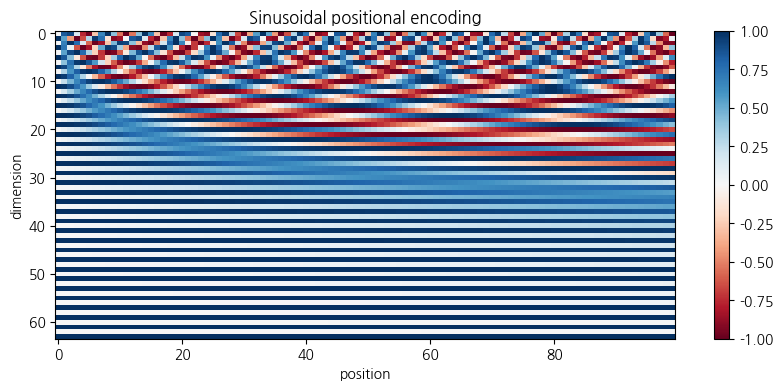

permutation equivariance: True


In [21]:
def positional_encoding(max_len, d_model):
    pe = torch.zeros(max_len, d_model)                  # (위치 수, 차원)
    pos = torch.arange(max_len).unsqueeze(1)            # 위치 0, 1, 2, ... → (max_len, 1)
    # 차원마다 다른 주파수: 1 / 10000^(2i/d_model)
    #   앞쪽 차원 = 빠르게 진동(가까운 위치 구별), 뒤쪽 차원 = 느리게 진동(먼 위치 구별)
    #   exp(-log(10000) * 2i/d) 형태로 계산하면 수치적으로 안정적
    div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(pos * div)                  # 짝수 차원: sin
    pe[:, 1::2] = torch.cos(pos * div)                  # 홀수 차원: cos
    return pe                                           # 실제 모델에서는 임베딩에 더해서 사용

pe = positional_encoding(100, 64)                       # 위치 100개, 64차원
plt.figure(figsize=(10, 4))
plt.imshow(pe.T, aspect="auto", cmap="RdBu")            # 세로=차원, 가로=위치 (빨강 +, 파랑 -)
plt.xlabel("position"); plt.ylabel("dimension"); plt.colorbar()
plt.title("Sinusoidal positional encoding"); plt.show()

# 순서 무관성 확인: 입력 순서를 바꾸면 출력도 같은 방식으로 바뀔 뿐
perm = torch.tensor([4, 3, 2, 1, 0])                    # 토큰 순서를 거꾸로
y_perm, _ = mha(X[perm].unsqueeze(0))                   # 뒤집은 입력으로 다시 계산
# "원래 출력을 뒤집은 것" == "뒤집은 입력의 출력" 이면 True
# → attention만으로는 순서를 구별 못 함 → 그래서 positional encoding이 필요
print("permutation equivariance:", torch.allclose(y[0, perm], y_perm[0], atol=1e-6))

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 히트맵: 위쪽(앞쪽 차원)은 줄무늬가 촘촘하고(빠른 진동), 아래쪽(뒤쪽 차원)으로 갈수록 넓어짐(느린 진동)
#   → 위치마다 sin/cos 값의 조합이 모두 달라 "위치 지문" 역할. 시계의 초침·분침·시침과 비슷한 원리
# - permutation equivariance: True
#   → 입력 순서를 거꾸로 하면 출력도 똑같이 거꾸로 될 뿐, 값 자체는 같음
#   → attention만으로는 "I love data"와 "data love I"를 구별 못 함 → positional encoding을 더하는 이유

---
# 3b. 사전학습 BERT의 attention 시각화

- `bert-base-uncased`: 12개 층 × 12개 head
- 고전적 예문: *"The animal didn't cross the street because **it** was too tired."*
- 질문: **it**은 어느 단어에 주목하는가?

In [22]:
from transformers import AutoTokenizer, AutoModel

name = "bert-base-uncased"                  # 영어 BERT (uncased: 대소문자 구분 없음)
tok = AutoTokenizer.from_pretrained(name)   # 문장 → 토큰 ID로 바꾸는 토크나이저
# output_attentions=True: 모든 층의 attention 가중치도 함께 반환
# .eval(): 평가 모드 (dropout 끔)
bert = AutoModel.from_pretrained(name, output_attentions=True).eval()

sentence = "The animal didn't cross the street because it was too tired."
inputs = tok(sentence, return_tensors="pt")             # PyTorch 텐서로 토큰화 (input_ids, attention_mask 등)
labels = tok.convert_ids_to_tokens(inputs["input_ids"][0])   # ID → 사람이 읽을 수 있는 토큰 문자열

with torch.no_grad():                                   # 추론만 하므로 기울기 계산 끔
    attentions = bert(**inputs).attentions   # 층별 (1, 12, T, T)  = (배치, head, Query, Key)
print("층 수:", len(attentions), " 형태:", attentions[0].shape)
print(labels)                               # [CLS]로 시작, [SEP]으로 끝남. didn't는 여러 조각으로 쪼개짐

# ============================================================
# [실행 결과 해설]
# ============================================================
# - "LOAD REPORT ... UNEXPECTED" 경고는 무시해도 됨: 사전학습 때 쓰던 cls.* (단어 맞히기 헤드) 가중치가
#   AutoModel(본체만)에는 필요 없어서 버려진다는 안내
# - 층 수 12, 형태 (1, 12, 16, 16) = (배치 1, head 12, Query 16, Key 16) → 토큰이 16개
# - 토큰화: [CLS]·[SEP] 특수 토큰 추가, 소문자화(uncased), "didn't"는 didn / ' / t 세 조각으로 쪼개짐
#   → 그래서 "it"은 10번(0부터), "animal"은 2번 위치

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


층 수: 12  형태: torch.Size([1, 12, 16, 16])
['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


## 7. 특정 층·head의 attention 행렬

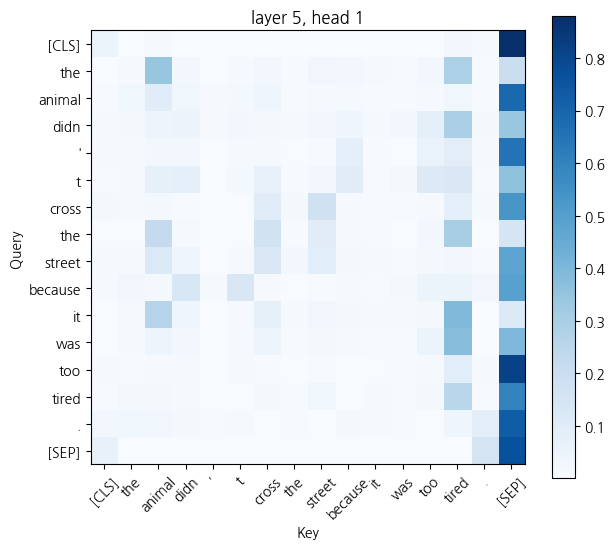

In [23]:
# 특정 층(layer)의 특정 head 하나의 attention 행렬을 히트맵으로
def plot_layer_head(layer, head):
    w = attentions[layer][0, head]          # [0]: 배치 첫 문장 → (T, T)
    plt.figure(figsize=(7, 6))
    show_attn(w, labels, f"layer {layer+1}, head {head+1}")   # 사람이 보기 쉽게 1부터 번호 표시

plot_layer_head(layer=4, head=0)            # 0부터 세므로 5번째 층, 1번째 head

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 5층 1번 head: 거의 모든 행에서 마지막 열 [SEP]이 가장 진함(0.5~0.85)
#   → BERT에서 잘 알려진 현상. 딱히 볼 곳이 없을 때 [SEP]/[CLS]에 가중치를 몰아 두는 "쉼터(no-op)" 역할
# - "it" 행: [SEP] 다음으로 tired, animal 쪽이 상대적으로 진함 → 서술어·주어 후보를 일부 참고
# - 교훈: head 하나만 보면 의미 있는 패턴이 잘 안 보일 수 있음 → 아래처럼 층별·head별로 넓게 살펴봐야 함

## 8. "it"이 주목하는 단어 — 층별 비교
- 각 층의 모든 head를 평균해 "it" 행만 추출
- 상위 층으로 갈수록 의미적 관계(it → animal)가 나타나는지 관찰

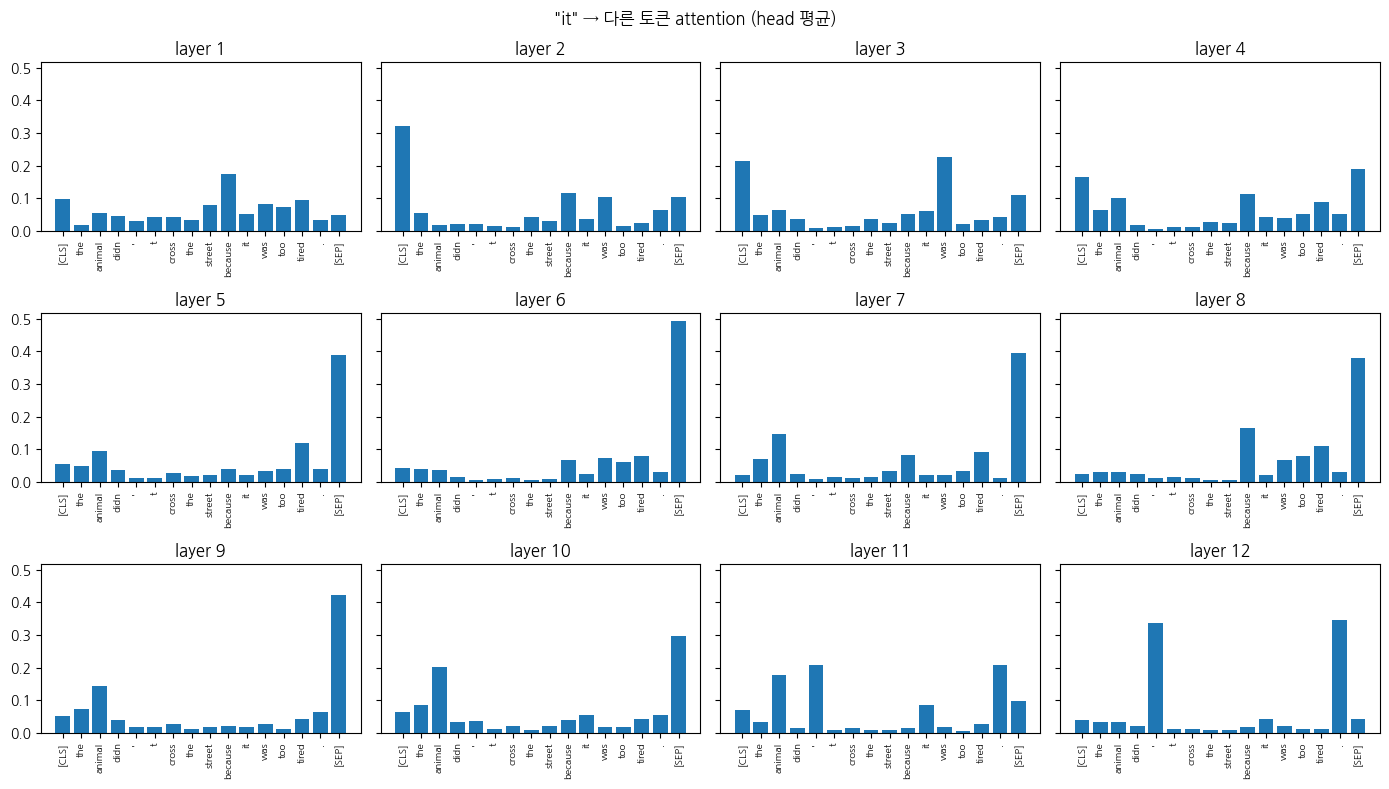

In [24]:
it_idx = labels.index("it")                 # 토큰 목록에서 "it"의 위치
fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharey=True)   # 12개 층 → 3×4 격자, y축 공유(비교 쉽게)
for L, ax in enumerate(axes.flat):
    # attentions[L][0, :, it_idx]: L층, 모든 head, Query="it" 행 → (12 heads, T)
    # .mean(0): 12개 head를 평균 → "it"이 각 토큰에 준 평균 가중치 (T,)
    w = attentions[L][0, :, it_idx].mean(0)      # head 평균
    ax.bar(range(len(labels)), w)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_title(f"layer {L+1}")
plt.suptitle('"it" → 다른 토큰 attention (head 평균)'); plt.tight_layout(); plt.show()

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 1~4층(하위): "it"이 [CLS], because, was 등 주변·특수 토큰에 고르게 분산 → 주로 위치·문법적 정보 처리
# - 5~9층(중간): [SEP]에 0.4~0.5로 크게 몰림 (위의 쉼터 현상). 그래도 animal 막대가 점점 커짐
# - 9~11층(상위): animal이 [SEP] 다음으로 큰 값(약 0.15~0.2)을 받음. street는 거의 0에 가까움
#   → 상위 층으로 갈수록 "it = animal"이라는 의미적(지시) 관계가 드러남
# - 12층: 따옴표(')와 마침표(.)에 몰림 → 마지막 층은 다음 작업용 표현을 정리하는 단계라 패턴이 달라짐
# - 주의: head 평균이라 특정 head의 강한 신호가 희석됨 → 다음 셀에서 head 단위로 찾아봄

최대: layer 4, head 11, weight=0.847


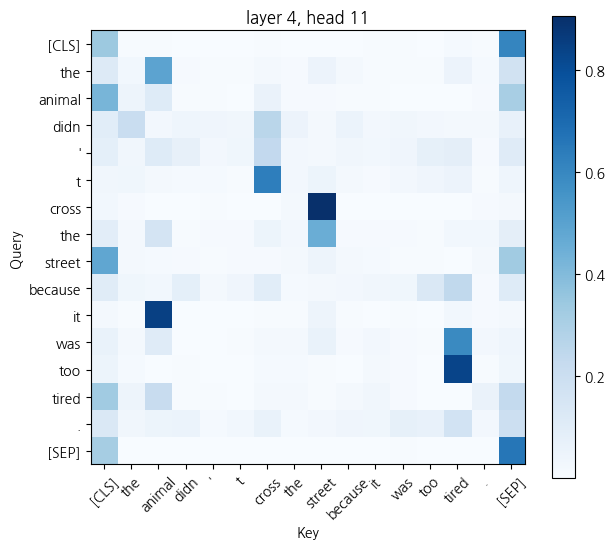

In [25]:
# 모든 층·head 중 "it" → "animal" 가중치가 가장 큰 곳 찾기
animal_idx = labels.index("animal")
# 12층 × 12head = 144개 조합의 (층, head, 가중치)를 만들고, 가중치(t[2]) 기준 최댓값 선택
best = max(((L, H, attentions[L][0, H, it_idx, animal_idx].item())
            for L in range(12) for H in range(12)), key=lambda t: t[2])
print(f"최대: layer {best[0]+1}, head {best[1]+1}, weight={best[2]:.3f}")
plot_layer_head(best[0], best[1])            # 그 head의 전체 attention 행렬 보기

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 144개 head 중 최대: layer 4, head 11에서 it → animal 가중치 0.847 (가중치의 85%를 animal 한 곳에 집중)
# - 그런데 이 head의 다른 행도 보면: the→animal, cross→street, too→tired, t→cross 처럼
#   "가까운 핵심 명사/서술어"를 가리키는 일정한 패턴이 있음
#   → 이 head가 "대명사 지시"를 이해한다기보다, 문법적으로 연결된 단어를 찾는 head일 가능성도 있음
# - 교훈: 최댓값 하나만 골라 보면 해석이 과장될 수 있음 → 과제 1처럼 문장을 바꿔 비교해 보는 것이 더 확실한 검증

## 9. (선택) 대화형 시각화 — BertViz

In [26]:
# BertViz: 층·head를 클릭하며 attention 연결선을 대화형으로 볼 수 있는 시각화 도구
!pip -q install bertviz
from bertviz import head_view
head_view(attentions, labels)   # 왼쪽 토큰에 마우스를 올리면 어느 토큰에 주목하는지 선으로 표시
                                # 위쪽 색 상자 = head 선택, Layer 드롭다운 = 층 선택

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 대화형 위젯이 출력됨: Layer 선택 + 색깔 상자(head)를 클릭하고, 왼쪽 "it"에 마우스를 올려 보기
# - 위의 정적 그래프에서 찾은 layer 4 / head 11, layer 7 / head 11 등을 직접 확인해 보면 좋음

<IPython.core.display.Javascript object>

## 10. 추가 과제
1. 문장을 *"...because **it** was too wide."*로 바꾸면 "it"의 주목 대상이 street로 바뀌는가?
2. 3a의 `MultiHeadAttention`에 잔차 연결·LayerNorm·FFN을 더해 Transformer 인코더 블록 하나를 완성하라.
3. 한국어 모델(`klue/bert-base`)로 바꿔 한국어 문장의 attention을 확인하라.
4. (토론) 실습 2의 교통량 예측에 Transformer를 쓴다면 입력을 어떻게 구성하고, causal mask가 필요한가?

### 추가 과제 1. "tired" → "wide"로 바꾸면 "it"의 주목 대상이 바뀌는가?
- 사람은 *tired*면 it = animal, *wide*면 it = street로 해석함 (의미에 따라 지시 대상이 달라지는 대표 예문, Winograd schema)
- 두 문장에서 층별로 "it → animal"과 "it → street" 가중치(head 평균)를 비교

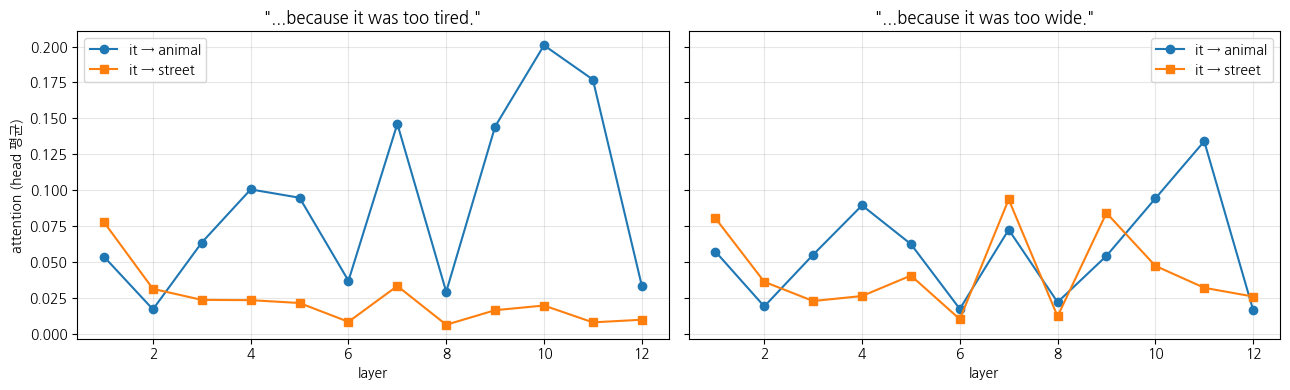

문장        animal(전체 평균)   street(전체 평균)   animal(상위 6층)   street(상위 6층)
tired             0.091           0.023           0.122           0.015
wide              0.058           0.042           0.065           0.049

문장에 따라 가장 민감하게 바뀌는 head: layer 7, head 11
  tired: animal 0.284 / street 0.067
  wide : animal 0.012 / street 0.590


In [27]:
# ===== 문장 → (토큰 목록, 층별 attention) 을 돌려주는 함수 =====
def get_attentions(sent, tokenizer=tok, model=bert):
    enc = tokenizer(sent, return_tensors="pt")
    with torch.no_grad():
        att = model(**enc).attentions                      # 층별 (1, heads, T, T)
    return tokenizer.convert_ids_to_tokens(enc["input_ids"][0]), att

sentences = {
    "tired": "The animal didn't cross the street because it was too tired.",
    "wide":  "The animal didn't cross the street because it was too wide.",
}

res = {}                                                    # {문장: (it→animal 층별, it→street 층별)}
for key, sent in sentences.items():
    lab, att = get_attentions(sent)
    i_it, i_an, i_st = lab.index("it"), lab.index("animal"), lab.index("street")
    # 층마다 12개 head 평균 → "it" 행에서 animal 열, street 열 값만 추출
    to_an = [att[L][0, :, i_it, i_an].mean().item() for L in range(12)]
    to_st = [att[L][0, :, i_it, i_st].mean().item() for L in range(12)]
    res[key] = (to_an, to_st)

# ===== 층별 비교 그래프 =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, key in zip(axes, res):
    to_an, to_st = res[key]
    ax.plot(range(1, 13), to_an, "o-", label="it → animal")
    ax.plot(range(1, 13), to_st, "s-", label="it → street")
    ax.set_title(f'"...because it was too {key}."'); ax.set_xlabel("layer")
    ax.legend(); ax.grid(alpha=.3)
axes[0].set_ylabel("attention (head 평균)")
plt.tight_layout(); plt.show()

# ===== 수치 요약 =====
print(f"{'문장':<7}{'animal(전체 평균)':>16}{'street(전체 평균)':>16}{'animal(상위 6층)':>16}{'street(상위 6층)':>16}")
for key, (to_an, to_st) in res.items():
    print(f"{key:<7}{sum(to_an)/12:>16.3f}{sum(to_st)/12:>16.3f}{sum(to_an[6:])/6:>16.3f}{sum(to_st[6:])/6:>16.3f}")

# ===== head 단위로 보면? "animal 쪽 - street 쪽" 차이가 두 문장에서 가장 크게 뒤집히는 head 찾기 =====
lab_t, att_t = get_attentions(sentences["tired"])
lab_w, att_w = get_attentions(sentences["wide"])
i_it, i_an, i_st = lab_t.index("it"), lab_t.index("animal"), lab_t.index("street")  # 두 문장의 토큰 위치는 동일
gap = lambda att, L, H: (att[L][0, H, i_it, i_an] - att[L][0, H, i_it, i_st]).item()  # +면 animal 선호
L, H, d = max(((L, H, gap(att_t, L, H) - gap(att_w, L, H)) for L in range(12) for H in range(12)),
              key=lambda t: t[2])
print(f"\n문장에 따라 가장 민감하게 바뀌는 head: layer {L+1}, head {H+1}")
print(f"  tired: animal {att_t[L][0,H,i_it,i_an]:.3f} / street {att_t[L][0,H,i_it,i_st]:.3f}")
print(f"  wide : animal {att_w[L][0,H,i_it,i_an]:.3f} / street {att_w[L][0,H,i_it,i_st]:.3f}")

# ============================================================
# [실행 결과 해설]
# ============================================================
# 문장    animal(전체)  street(전체)  animal(상위6층)  street(상위6층)
# tired      0.091        0.023         0.122           0.015
# wide       0.058        0.042         0.065           0.049
#
# Q. "wide"로 바꾸면 it의 주목 대상이 street로 바뀌는가?  → "부분적으로 그렇다"
# - head 평균(그래프): tired 문장은 거의 모든 층에서 animal >> street (상위 층에서 약 8배)
#   wide 문장은 격차가 크게 줄고, 7·9층에서는 street가 animal을 앞지름
#   단, 전체 평균으로는 여전히 animal이 조금 더 높음 → 완전히 뒤집히진 않음
# - head 단위: layer 7, head 11은 확실히 뒤집힘
#   tired: animal 0.284 / street 0.067   →   wide: animal 0.012 / street 0.590
#   → BERT 안에 문맥(형용사 의미)에 따라 지시 대상을 바꾸는 head가 존재한다는 증거
# - 주의: 이 head는 "차이가 가장 큰 것"을 골라서 찾은 것이라 선택 편향이 있음
#   여러 예문에서 같은 head가 일관되게 반응하는지 확인해야 일반화할 수 있음
# - 해석: attention은 여러 head에 정보가 나뉘어 있고, 평균만 보면 미묘한 의미 차이가 묻힐 수 있음

### 추가 과제 2. Transformer 인코더 블록 완성하기
- 구조 (원 논문과 같은 **Post-LN** 방식):
  1. `x = LayerNorm(x + Dropout(MultiHeadAttention(x)))`  ← 잔차 연결 + 정규화
  2. `x = LayerNorm(x + Dropout(FFN(x)))`  ← FFN: Linear(d → 4d) → ReLU → Linear(4d → d)
- **잔차 연결**: 입력을 출력에 더해 줘서 층을 깊게 쌓아도 기울기가 잘 흐름
- **LayerNorm**: 토큰 벡터마다 평균 0·분산 1로 맞춰 학습 안정화
- **FFN**: attention이 "토큰 간 정보 교환"이라면, FFN은 "토큰 각자의 표현을 비선형으로 가공"
- 검증: PyTorch 내장 `nn.TransformerEncoderLayer`에 같은 가중치를 넣고 출력이 같은지 비교

In [28]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff=None, dropout=0.1):
        super().__init__()
        d_ff = d_ff or 4 * d_model                     # FFN 은닉 차원: 보통 d_model의 4배
        self.attn = MultiHeadAttention(d_model, n_heads)   # 3a에서 직접 만든 모듈 재사용
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.ReLU(),       # 확장 (d → 4d) + 비선형
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),                  # 축소 (4d → d)
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop1 = nn.Dropout(dropout)
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x, mask=None):                   # x: (batch, seq, d_model)
        a, w = self.attn(x, mask)                      # (1) 토큰 간 정보 교환
        x = self.norm1(x + self.drop1(a))              #     잔차 연결 + LayerNorm
        x = self.norm2(x + self.drop2(self.ffn(x)))    # (2) 토큰별 가공 + 잔차 연결 + LayerNorm
        return x, w                                    # 입력과 같은 모양 → 블록을 여러 개 쌓을 수 있음

# ===== 동작 확인 =====
block = TransformerEncoderBlock(d_model=8, n_heads=2).eval()   # eval(): 비교를 위해 dropout 끔
z, wz = block(X.unsqueeze(0))
print("입력:", tuple(X.unsqueeze(0).shape), "→ 출력:", tuple(z.shape), " attention:", tuple(wz.shape))

# ===== 내장 nn.TransformerEncoderLayer와 비교 =====
ref_layer = nn.TransformerEncoderLayer(d_model=8, nhead=2, dim_feedforward=32,
                                       dropout=0.1, batch_first=True).eval()   # 기본값 = Post-LN, ReLU
with torch.no_grad():
    ref_layer.self_attn.in_proj_weight.copy_(block.attn.W_qkv.weight)
    ref_layer.self_attn.in_proj_bias.copy_(block.attn.W_qkv.bias)
    ref_layer.self_attn.out_proj.weight.copy_(block.attn.W_o.weight)
    ref_layer.self_attn.out_proj.bias.copy_(block.attn.W_o.bias)
    ref_layer.linear1.load_state_dict(block.ffn[0].state_dict())   # FFN 첫 번째 Linear
    ref_layer.linear2.load_state_dict(block.ffn[3].state_dict())   # FFN 두 번째 Linear
    ref_layer.norm1.load_state_dict(block.norm1.state_dict())
    ref_layer.norm2.load_state_dict(block.norm2.state_dict())
    z_ref = ref_layer(X.unsqueeze(0))

count = lambda m: sum(p.numel() for p in m.parameters())
print("파라미터 수 — 직접 구현:", count(block), " / 내장:", count(ref_layer))
print("최대 오차:", (z - z_ref).abs().max().item())
print("일치 여부:", torch.allclose(z, z_ref, atol=1e-5))

# ===== 블록 쌓기: 출력 모양이 입력과 같아서 N개를 그대로 연결 가능 =====
encoder = nn.ModuleList([TransformerEncoderBlock(8, 2) for _ in range(6)]).eval()   # 원 논문: 6층
h = X.unsqueeze(0) + positional_encoding(seq_len, 8)     # 위치 정보를 더해서 입력
for blk in encoder:
    h, _ = blk(h)
print("6층 인코더 출력:", tuple(h.shape), " 총 파라미터:", count(encoder))

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 입력과 출력 모양이 (1, 5, 8)로 같음 → 같은 블록을 원하는 만큼 쌓을 수 있음
# - 파라미터 872개로 내장 nn.TransformerEncoderLayer와 동일, 최대 오차 0.0 → 구조가 완전히 일치
#   · MHA: W_qkv 8×24+24 = 216, W_o 8×8+8 = 72        → 288
#   · FFN: 8×32+32 = 288, 32×8+8 = 264                  → 552
#   · LayerNorm 2개: (8+8)×2                             →  32    합계 872
#   → 파라미터의 약 63%가 FFN에 있음 (실제 대형 모델에서도 FFN 비중이 큼)
# - 6층 인코더: 872 × 6 = 5,232개. 원 논문의 기본 Transformer 인코더(6층)와 같은 구성

입력: (1, 5, 8) → 출력: (1, 5, 8)  attention: (1, 2, 5, 5)
파라미터 수 — 직접 구현: 872  / 내장: 872
최대 오차: 0.0
일치 여부: True
6층 인코더 출력: (1, 5, 8)  총 파라미터: 5232


### 추가 과제 3. 한국어 모델 `klue/bert-base`로 attention 확인하기
- KLUE: 한국어 자연어 이해 벤치마크, `klue/bert-base`는 한국어 데이터로 사전학습된 BERT (12층 × 12 head)
- 영어 예문과 같은 구조의 한국어 문장 두 개로 "그것"이 누구에게 주목하는지 비교
- 한국어는 조사·어미가 붙어 **형태소 단위로 쪼개짐** (예: `동물` + `##은`) → 토큰화 결과도 함께 확인

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[피곤] 토큰화: ['[CLS]', '동물', '##은', '길', '##을', '건너', '##지', '않', '##았', '##다', '.', '왜냐하면', '그것', '##은', '너무', '피곤', '##했', '##기', '때문', '##이다', '.', '[SEP]']
[넓음] 토큰화: ['[CLS]', '동물', '##은', '길', '##을', '건너', '##지', '않', '##았', '##다', '.', '왜냐하면', '그것', '##은', '너무', '넓', '##었', '##기', '때문', '##이다', '.', '[SEP]']


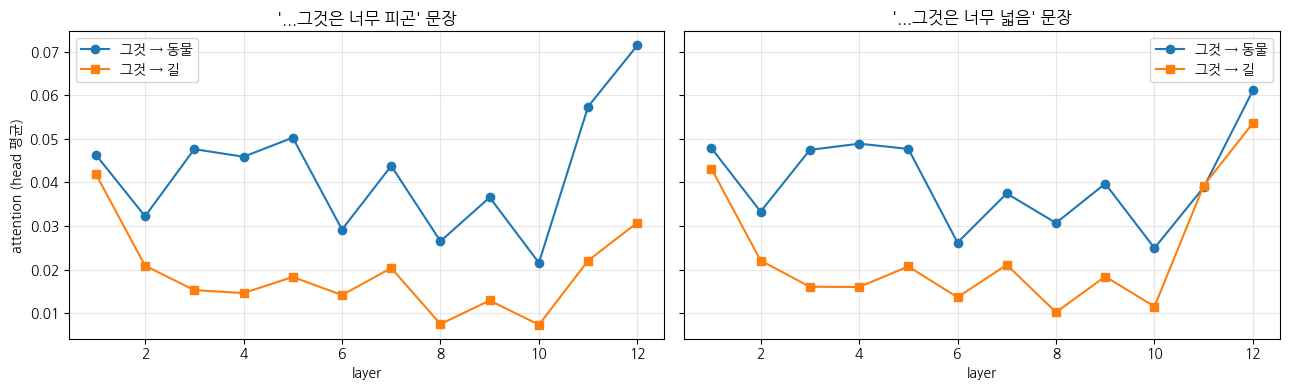


문장         동물(전체 평균)      길(전체 평균)     동물(상위 6층)      길(상위 6층)
피곤             0.042         0.019         0.043         0.017
넓음             0.040         0.024         0.039         0.026

[피곤 문장] '그것'의 층별 Top 3 주목 토큰
  layer  1: 왜냐하면(0.09), 피곤(0.08), 너무(0.08)
  layer  2: ##은(0.13), 왜냐하면(0.07), ##이다(0.06)
  layer  3: ##은(0.20), ##은(0.05), 동물(0.05)
  layer  4: ##은(0.06), ##은(0.06), 왜냐하면(0.05)
  layer  5: 왜냐하면(0.13), 동물(0.05), ##다(0.04)
  layer  6: 왜냐하면(0.14), ##은(0.08), ##은(0.05)
  layer  7: ##은(0.13), 왜냐하면(0.10), 피곤(0.07)
  layer  8: 피곤(0.10), ##은(0.06), 왜냐하면(0.05)
  layer  9: ##은(0.04), 동물(0.04), ##했(0.03)
  layer 10: ##은(0.10), ##이다(0.04), ##은(0.03)
  layer 11: 동물(0.06), 피곤(0.03), 길(0.02)
  layer 12: 동물(0.07), ##을(0.04), 피곤(0.04)


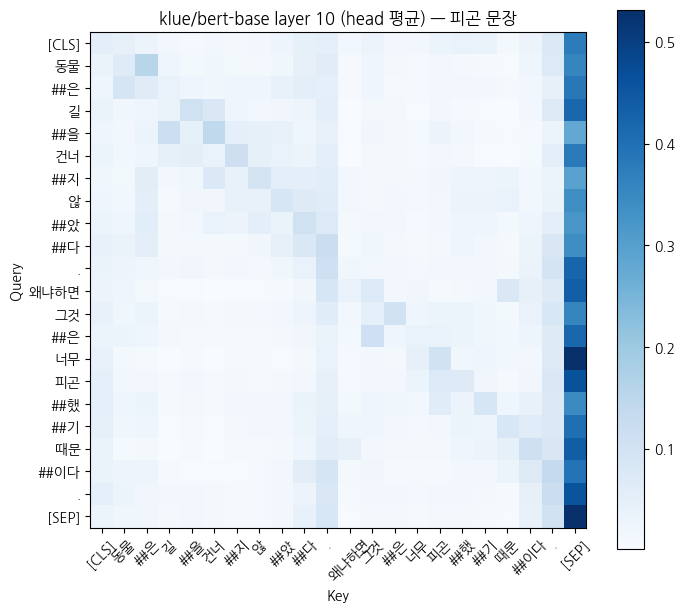

In [29]:
from transformers import AutoTokenizer, AutoModel

ko_name = "klue/bert-base"
ko_tok = AutoTokenizer.from_pretrained(ko_name)
ko_bert = AutoModel.from_pretrained(ko_name, output_attentions=True).eval()

ko_sentences = {
    "피곤": "동물은 길을 건너지 않았다. 왜냐하면 그것은 너무 피곤했기 때문이다.",
    "넓음": "동물은 길을 건너지 않았다. 왜냐하면 그것은 너무 넓었기 때문이다.",
}

# 토큰 목록에서 특정 단어로 시작하는 첫 토큰의 위치 찾기 (서브워드의 ## 표시는 제거하고 비교)
def find(labels_, word):
    return next(i for i, t in enumerate(labels_) if t.replace("##", "").startswith(word))

ko_res = {}
for key, sent in ko_sentences.items():
    lab, att = get_attentions(sent, ko_tok, ko_bert)
    print(f"[{key}] 토큰화:", lab)
    i_it, i_an, i_rd = find(lab, "그것"), find(lab, "동물"), find(lab, "길")
    to_an = [att[L][0, :, i_it, i_an].mean().item() for L in range(12)]   # 그것 → 동물
    to_rd = [att[L][0, :, i_it, i_rd].mean().item() for L in range(12)]   # 그것 → 길
    ko_res[key] = (to_an, to_rd, lab, att, i_it)

# ===== 층별 비교 =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, key in zip(axes, ko_res):
    to_an, to_rd = ko_res[key][:2]
    ax.plot(range(1, 13), to_an, "o-", label="그것 → 동물")
    ax.plot(range(1, 13), to_rd, "s-", label="그것 → 길")
    ax.set_title(f"'...그것은 너무 {key}' 문장"); ax.set_xlabel("layer"); ax.legend(); ax.grid(alpha=.3)
axes[0].set_ylabel("attention (head 평균)")
plt.tight_layout(); plt.show()

print(f"\n{'문장':<6}{'동물(전체 평균)':>14}{'길(전체 평균)':>14}{'동물(상위 6층)':>14}{'길(상위 6층)':>14}")
for key, (to_an, to_rd, *_ ) in ko_res.items():
    print(f"{key:<6}{sum(to_an)/12:>14.3f}{sum(to_rd)/12:>14.3f}{sum(to_an[6:])/6:>14.3f}{sum(to_rd[6:])/6:>14.3f}")

# ===== "그것"이 가장 많이 주목한 토큰 Top 3 (층별, 특수 토큰·자기 자신 제외) =====
lab, att, i_it = ko_res["피곤"][2], ko_res["피곤"][3], ko_res["피곤"][4]
print("\n[피곤 문장] '그것'의 층별 Top 3 주목 토큰")
for L in range(12):
    w = att[L][0, :, i_it].mean(0).clone()
    for j, t in enumerate(lab):
        if t in ("[CLS]", "[SEP]", ".") or j == i_it:
            w[j] = -1                                   # 제외
    top = w.topk(3).indices.tolist()
    print(f"  layer {L+1:>2}: " + ", ".join(f"{lab[j]}({w[j]:.2f})" for j in top))

# ===== 한 층 전체 attention 히트맵 (head 평균) =====
labels_backup = labels                                 # show_attn은 labels를 인자로 받으므로 영향 없음
plt.figure(figsize=(8, 7))
show_attn(att[9][0].mean(0), lab, "klue/bert-base layer 10 (head 평균) — 피곤 문장")

# ============================================================
# [실행 결과 해설]
# ============================================================
# - 토큰화: 한국어는 형태소 단위로 쪼개짐 → 동물 + ##은, 그것 + ##은, 피곤 + ##했 + ##기, 넓 + ##었 + ##기
#   → 영어보다 토큰 수가 많고(22개), "조사"가 별도 토큰이라 attention이 조사로도 분산됨
#
# 문장   동물(전체)  길(전체)  동물(상위6층)  길(상위6층)
# 피곤     0.042      0.019      0.043         0.017
# 넓음     0.040      0.024      0.039         0.026
# - 두 문장 모두 "그것 → 동물"이 "그것 → 길"보다 높고, 넓음 문장에서 길 쪽이 조금 올라감(0.017 → 0.026)
#   → 방향은 영어와 같지만 차이가 매우 작아 "주목 대상이 바뀌었다"고 보기는 어려움
# - Top 3 토큰: 하위~중간 층은 바로 뒤 조사(##은), 접속사(왜냐하면), 서술어(피곤)에 주로 주목
#   → 주어-서술어 같은 문법 관계 위주. 11·12층에 와서야 동물이 1위로 등장
# - 영어보다 신호가 약한 이유(추정):
#   · 조사·어미로 쪼개져 가중치가 여러 토큰에 분산됨 ("동물" 토큰만 셌고 "##은"은 제외)
#   · 한국어는 "그것" 같은 대명사보다 생략을 많이 써서, 사전학습 데이터에 이런 문장 구조가 드묾
#   · head 평균이라 특정 head의 신호가 희석됨 → 과제 1처럼 head 단위로 찾아보면 더 뚜렷할 수 있음
# - 마지막 히트맵(10층): 많은 토큰이 [CLS]/[SEP] 같은 특수 토큰과 인접 토큰에 주목하는 패턴

### 추가 과제 4. (토론) 실습 2의 교통량 예측에 Transformer를 쓴다면?

**1. 입력 구성: "1시간 = 토큰 1개"**
- 실습 2에서 LSTM에 넣던 시퀀스를 그대로 토큰열로 봐요. `WINDOW=168`이면 토큰 168개예요.
- 각 토큰의 특성 벡터: `[교통량, sin/cos(시각), sin/cos(요일), 주말 여부, (공휴일·날씨 등)]` → `nn.Linear(n_feat, d_model)`로 d_model 차원 임베딩으로 변환 (BERT의 단어 임베딩 역할)
- **위치 정보 추가가 필수**예요. attention은 순서를 모르기 때문이에요 (6번 셀의 permutation equivariance 결과). 3a의 sinusoidal positional encoding을 더하거나, 학습 가능한 위치 임베딩을 써요. 시각·요일 sin/cos 특성은 일종의 "달력 위치 인코딩" 역할도 해요.
- 출력: 마지막 토큰의 출력 벡터(또는 [CLS] 같은 요약 토큰)를 `nn.Linear(d_model, 1)`에 넣어 다음 1시간 교통량을 예측해요.

```python
x = proj(features) + positional_encoding(168, d_model)   # (batch, 168, d_model)
for blk in encoder: x, w = blk(x, mask)                   # 과제 2의 인코더 블록 재사용
pred = head(x[:, -1, :])                                  # 마지막 시점 → 다음 1시간
```

**2. causal mask가 필요한가? → "어떻게 학습하느냐"에 따라 달라요**
- **필요 없는 경우**: 윈도우 168시간 전체를 보고 **그다음 1시간만** 예측하는 방식 (실습 2와 같은 구조)
  - 입력 168개가 전부 예측 시점보다 과거라서 서로 자유롭게 봐도 미래 정보가 새지 않아요.
  - BERT처럼 양방향 attention을 써도 돼요.
- **필요한 경우**: 윈도우 안의 **모든 시점에서 각각 다음 값을 예측**하도록 학습할 때 (GPT 방식, 168개 위치에서 동시에 손실 계산)
  - t번째 토큰이 t+1 이후를 보면 정답을 베끼는 셈이라 causal mask로 막아야 해요 (3번 셀의 하삼각 마스크).
  - 여러 시간 뒤까지 한 시간씩 이어서 예측(자기회귀, autoregressive)하는 다단계 예측에서도 필요해요.
- 어느 경우든 **학습/테스트를 시간 순서로 나누고, 정규화 통계를 학습 구간에서만 계산**하는 원칙은 그대로예요 (실습 2와 동일). causal mask는 모델 내부의 누출을, 시간 순 분할은 데이터 수준의 누출을 막아요.

**3. LSTM 대비 기대 효과와 주의점**
- 168시간 전(지난주 같은 시각)과 24시간 전(어제 같은 시각)에 거리 1로 바로 접근할 수 있어요. 실습 2에서 LSTM이 긴 윈도우를 활용하지 못했던 한계를 해결해요.
- 학습 후 attention 가중치를 보면 t-24, t-168 위치가 진하게 나타나는지 확인할 수 있어요. 해석이 가능하다는 장점이에요 (3b에서 BERT를 시각화한 것처럼).
- 주의: 계산량이 시퀀스 길이의 제곱(168² ≈ 2.8만)이에요. 이 정도는 문제없지만 몇 달치 시간 단위 데이터라면 부담이 돼요. 그럴 땐 여러 시간을 묶어 한 토큰으로 만드는 patch 방식(PatchTST 등)을 써요.
- 데이터가 2,880개로 작아서 큰 Transformer는 과적합되기 쉬워요. 작은 d_model(16~32), 1~2층, dropout으로 시작하는 게 좋아요. 실제로 이런 규모에서는 MLP·LSTM이 Transformer보다 나은 경우도 흔해요.